In [1]:
import numpy as np
DATA_PATH = r'raw_data\record_2024_0929_1727\vehicle.tesla.model3.master\velodyne_semantic\0000002484.npy'

# ==============================================================================
#                                                                   SCALE_TO_255
# ==============================================================================
def scale_to_255(a, min, max, dtype=np.uint8):
    """ Scales an array of values from specified min, max range to 0-255
        Optionally specify the data type of the output (default is uint8)
    """
    return (((a - min) / float(max - min)) * 255).astype(dtype)


# ==============================================================================
#                                                         POINT_CLOUD_2_BIRDSEYE
# ==============================================================================
def point_cloud_2_birdseye(points,
                           res=0.5,
                           side_range=(-100., 100.),  # left-most to right-most
                           fwd_range = (-100., 100.), # back-most to forward-most
                           height_range=(-3., 3.),  # bottom-most to upper-most
                           ):
    """ Creates an 2D birds eye view representation of the point cloud data.

    Args:
        points:     (numpy array)
                    N rows of points data
                    Each point should be specified by at least 3 elements x,y,z
        res:        (float)
                    Desired resolution in metres to use. Each output pixel will
                    represent an square region res x res in size.
        side_range: (tuple of two floats)
                    (-left, right) in metres
                    left and right limits of rectangle to look at.
        fwd_range:  (tuple of two floats)
                    (-behind, front) in metres
                    back and front limits of rectangle to look at.
        height_range: (tuple of two floats)
                    (min, max) heights (in metres) relative to the origin.
                    All height values will be clipped to this min and max value,
                    such that anything below min will be truncated to min, and
                    the same for values above max.
    Returns:
        2D numpy array representing an image of the birds eye view.
    """
    # EXTRACT THE POINTS FOR EACH AXIS
    x_points = points['x']
    y_points = points['y']
    z_points = points['z']

    # FILTER - To return only indices of points within desired cube
    # Three filters for: Front-to-back, side-to-side, and height ranges
    # Note left side is positive y axis in LIDAR coordinates
    f_filt = np.logical_and((x_points > fwd_range[0]), (x_points < fwd_range[1]))
    s_filt = np.logical_and((y_points > -side_range[1]), (y_points < -side_range[0]))
    filter = np.logical_and(f_filt, s_filt)
    indices = np.argwhere(filter).flatten()

    # KEEPERS
    x_points = x_points[indices]
    y_points = y_points[indices]
    z_points = z_points[indices]

    # CONVERT TO PIXEL POSITION VALUES - Based on resolution
    x_img = (-y_points / res).astype(np.int32)  # x axis is -y in LIDAR
    y_img = (-x_points / res).astype(np.int32)  # y axis is -x in LIDAR

    # SHIFT PIXELS TO HAVE MINIMUM BE (0,0)
    # floor & ceil used to prevent anything being rounded to below 0 after shift
    x_img -= int(np.floor(side_range[0] / res))
    y_img += int(np.ceil(fwd_range[1] / res))

    # CLIP HEIGHT VALUES - to between min and max heights
    pixel_values = np.clip(a=z_points,
                           a_min=height_range[0],
                           a_max=height_range[1])

    # RESCALE THE HEIGHT VALUES - to be between the range 0-255
    pixel_values = scale_to_255(pixel_values,
                                min=height_range[0],
                                max=height_range[1])

    # INITIALIZE EMPTY ARRAY - of the dimensions we want
    x_max = 1 + int((side_range[1] - side_range[0]) / res)
    y_max = 1 + int((fwd_range[1] - fwd_range[0]) / res)
    im = np.zeros([y_max, x_max], dtype=np.uint8)

    # FILL PIXEL VALUES IN IMAGE ARRAY
    im[y_img, x_img] = pixel_values

    return im

In [2]:
points = np.load(DATA_PATH)

In [3]:
points

array([(8.795693 , 13.052392 ,  4.2173643, 0.17581967, -6.8073646e-08, 0.000000e+00, -0.0000000e+00,  0.0000000e+00, 0.0000000e+00, 0.93690014, 2060,  5),
       (8.779619 , 13.000293 ,  4.2033796, 0.17646392, -6.8076162e-08, 0.000000e+00, -0.0000000e+00,  0.0000000e+00, 0.0000000e+00, 0.9371026 , 2060,  5),
       (8.765869 , 12.951884 ,  4.19057  , 0.45528433, -6.8078677e-08, 0.000000e+00, -0.0000000e+00,  0.0000000e+00, 0.0000000e+00, 0.93728817, 2060,  5),
       ...,
       (1.5031836, -2.5855663, -1.3819282, 0.8841214 ,  5.9426759e-07, 9.851433e-09, -9.2718215e-09, -1.1539458e-06, 4.8780265e-07, 0.986908  , 2160, 10),
       (1.4998926, -2.585869 , -1.3812828, 0.8845339 ,  5.9428112e-07, 9.851433e-09, -9.2718215e-09, -1.1539458e-06, 4.8781396e-07, 0.9869141 , 2160, 10),
       (1.4965918, -2.5861719, -1.380639 , 0.88494706,  5.9429550e-07, 9.851433e-09, -9.2718215e-09, -1.1539458e-06, 4.8782607e-07, 0.9869201 , 2160, 10)],
      dtype=[('x', '<f4'), ('y', '<f4'), ('z', '<f4'), ('

In [4]:
img = point_cloud_2_birdseye(points)

In [5]:
img

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

In [6]:
from PIL import Image
im2 = Image.fromarray(img)
im2.show()

In [7]:
def lidar_to_2d_front_view(points,
                           v_res,
                           h_res,
                           v_fov,
                           val="depth",
                           cmap="jet",
                           saveto=None,
                           y_fudge=0.0
                           ):
    """ Takes points in 3D space from LIDAR data and projects them to a 2D
        "front view" image, and saves that image.

    Args:
        points: (np array)
            The numpy array containing the lidar points.
            The shape should be Nx4
            - Where N is the number of points, and
            - each point is specified by 4 values (x, y, z, reflectance)
        v_res: (float)
            vertical resolution of the lidar sensor used.
        h_res: (float)
            horizontal resolution of the lidar sensor used.
        v_fov: (tuple of two floats)
            (minimum_negative_angle, max_positive_angle)
        val: (str)
            What value to use to encode the points that get plotted.
            One of {"depth", "height", "reflectance"}
        cmap: (str)
            Color map to use to color code the `val` values.
            NOTE: Must be a value accepted by matplotlib's scatter function
            Examples: "jet", "gray"
        saveto: (str or None)
            If a string is provided, it saves the image as this filename.
            If None, then it just shows the image.
        y_fudge: (float)
            A hacky fudge factor to use if the theoretical calculations of
            vertical range do not match the actual data.

            For a Velodyne HDL 64E, set this value to 5.
    """

    # DUMMY PROOFING
    assert len(v_fov) ==2, "v_fov must be list/tuple of length 2"
    assert v_fov[0] <= 0, "first element in v_fov must be 0 or negative"
    assert val in {"depth", "height", "reflectance"}, \
        'val must be one of {"depth", "height", "reflectance"}'


    x_lidar = points['x']
    y_lidar = points['y']
    z_lidar = points['z']
    r_lidar = points['intensity'] # Reflectance
    # Distance relative to origin when looked from top
    d_lidar = np.sqrt(x_lidar ** 2 + y_lidar ** 2)
    # Absolute distance relative to origin
    # d_lidar = np.sqrt(x_lidar ** 2 + y_lidar ** 2, z_lidar ** 2)

    v_fov_total = -v_fov[0] + v_fov[1]

    # Convert to Radians
    v_res_rad = v_res * (np.pi/180)
    h_res_rad = h_res * (np.pi/180)

    # PROJECT INTO IMAGE COORDINATES
    x_img = np.arctan2(-y_lidar, x_lidar)/ h_res_rad
    y_img = np.arctan2(z_lidar, d_lidar)/ v_res_rad

    # SHIFT COORDINATES TO MAKE 0,0 THE MINIMUM
    x_min = -360.0 / h_res / 2  # Theoretical min x value based on sensor specs
    x_img -= x_min              # Shift
    x_max = 360.0 / h_res       # Theoretical max x value after shifting

    y_min = v_fov[0] / v_res    # theoretical min y value based on sensor specs
    y_img -= y_min              # Shift
    y_max = v_fov_total / v_res # Theoretical max x value after shifting

    y_max += y_fudge            # Fudge factor if the calculations based on
                                # spec sheet do not match the range of
                                # angles collected by in the data.

    # WHAT DATA TO USE TO ENCODE THE VALUE FOR EACH PIXEL
    if val == "reflectance":
        pixel_values = r_lidar
    elif val == "height":
        pixel_values = z_lidar
    else:
        pixel_values = -d_lidar

    # PLOT THE IMAGE
    cmap = "jet"            # Color map to use
    dpi = 100               # Image resolution
    fig, ax = plt.subplots(figsize=(x_max/dpi, y_max/dpi), dpi=dpi)
    ax.scatter(x_img,y_img, s=1, c=pixel_values, linewidths=0, alpha=1, cmap=cmap)
    ax.set_facecolor((0, 0, 0)) # Set regions with no points to black
    ax.axis('scaled')              # {equal, scaled}
    ax.xaxis.set_visible(False)    # Do not draw axis tick marks
    ax.yaxis.set_visible(False)    # Do not draw axis tick marks
    plt.xlim([0, x_max])   # prevent drawing empty space outside of horizontal FOV
    plt.ylim([0, y_max])   # prevent drawing empty space outside of vertical FOV

    if saveto is not None:
        fig.savefig(saveto, dpi=dpi, bbox_inches='tight', pad_inches=0.0)
    else:
        fig.show()

C:\Users\zrtC103\AppData\Local\Temp\ipykernel_23580\4141158759.py:104: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


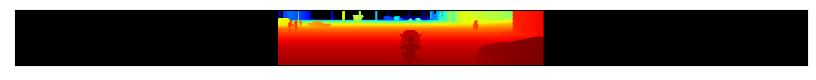

In [8]:
import matplotlib.pyplot as plt
import numpy as np

HRES = 0.35         # horizontal resolution (assuming 20Hz setting)
VRES = 0.4          # vertical res
VFOV = (-24.9, 2.0) # Field of view (-ve, +ve) along vertical axis
Y_FUDGE = 5         # y fudge factor for velodyne HDL 64E

lidar_to_2d_front_view(points, v_res=VRES, h_res=HRES, v_fov=VFOV, val="reflectance", y_fudge=Y_FUDGE)